In [2]:
!pip install -q kagglehub

In [3]:
import os
from pathlib import Path
from collections import Counter

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from IPython.display import display

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
os.environ["KAGGLE_API_TOKEN"] = "KGAT_b3ae8f4633adb701b31db859d5fff936"

print("Kaggle API token configured.")

Kaggle API token configured.


In [5]:
# Download PlantVillage using KaggleHub
path = kagglehub.dataset_download("aftaabahmedshaik/plantvillage-dataset")

print("Dataset download successfully.")
print("Dataset path:", path)

100%|██████████| 816M/816M [00:10<00:00, 84.0MB/s] 

Extracting files...


Dataset download successfully.
Dataset path: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1


In [6]:
# Inspect the downloaded files
dataset_path = Path(path)

print("Dataset root:")
print(dataset_path)

print("\nTop-level contents:")
for item in sorted(dataset_path.iterdir()):
  if item.is_dir():
    print(f"[DIR] {item.name}")
  else:
    print(f"[FILE] {item.name}")

Dataset root:
/root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1

Top-level contents:
[DIR] color


In [7]:
def show_directory_tree(root_path, max_depth=2):
    root_path = Path(root_path)

    for current_path, dirs, files in os.walk(root_path):
        relative = Path(current_path).relative_to(root_path)
        depth = len(relative.parts)

        if depth > max_depth:
            dirs[:] = []
            continue

        indent = "    " * depth
        folder_name = root_path.name if depth == 0 else Path(current_path).name

        print(f"{indent}📁 {folder_name}/")

        if files:
            print(f"{indent}    └── {len(files)} files")


show_directory_tree(dataset_path, max_depth=3)

📁 1/
    📁 color/
        📁 Cherry_(including_sour)___Powdery_mildew/
            └── 1052 files
        📁 Cherry_(including_sour)___healthy/
            └── 854 files
        📁 Corn_(maize)___healthy/
            └── 1162 files
        📁 Tomato___Spider_mites Two-spotted_spider_mite/
            └── 1676 files
        📁 Grape___Esca_(Black_Measles)/
            └── 1383 files
        📁 Tomato___Early_blight/
            └── 1000 files
        📁 Strawberry___Leaf_scorch/
            └── 1109 files
        📁 Grape___healthy/
            └── 423 files
        📁 Tomato___Bacterial_spot/
            └── 2127 files
        📁 Apple___Cedar_apple_rust/
            └── 275 files
        📁 Tomato___Septoria_leaf_spot/
            └── 1771 files
        📁 Strawberry___healthy/
            └── 456 files
        📁 Potato___Early_blight/
            └── 1000 files
        📁 Corn_(maize)___Common_rust_/
            └── 1192 files
        📁 Grape___Black_rot/
            └── 1180 files
        📁 Toma

Create one clean dataframe representing every image. Everything else can be calcuated from that dataframe (class counts, crop counts, imbalance analysis, image properties, duplicate checks):

In [8]:
# Cell 7: Set the actual image directory

# Set the directory containing the 30 PlantVillage classes
image_dir = dataset_path / "color"

print("Image directory:", image_dir)
print("Directory exists:", image_dir.exists())

Image directory: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1/color
Directory exists: True


In [9]:
# Cell 8: Get all class folders automatically
class_folders = sorted([
    folder for folder in image_dir.iterdir()
    if folder.is_dir()
])

class_names = [folder.name for folder in class_folders]

print("Total number of classes:", len(class_names))

print("\nClass names:")
for i, class_name in enumerate(class_names, start=1):
  print(f"{i:2d}. {class_name}")

Total number of classes: 38

Class names:
 1. Apple___Apple_scab
 2. Apple___Black_rot
 3. Apple___Cedar_apple_rust
 4. Apple___healthy
 5. Blueberry___healthy
 6. Cherry_(including_sour)___Powdery_mildew
 7. Cherry_(including_sour)___healthy
 8. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 9. Corn_(maize)___Common_rust_
10. Corn_(maize)___Northern_Leaf_Blight
11. Corn_(maize)___healthy
12. Grape___Black_rot
13. Grape___Esca_(Black_Measles)
14. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15. Grape___healthy
16. Orange___Haunglongbing_(Citrus_greening)
17. Peach___Bacterial_spot
18. Peach___healthy
19. Pepper,_bell___Bacterial_spot
20. Pepper,_bell___healthy
21. Potato___Early_blight
22. Potato___Late_blight
23. Potato___healthy
24. Raspberry___healthy
25. Soybean___healthy
26. Squash___Powdery_mildew
27. Strawberry___Leaf_scorch
28. Strawberry___healthy
29. Tomato___Bacterial_spot
30. Tomato___Early_blight
31. Tomato___Late_blight
32. Tomato___Leaf_Mold
33. Tomato___Septoria_leaf

In [10]:
# Cell 9: Create the image inventory dataframe

# Supported image file extensions
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_records = []

for class_folder in class_folders:
  class_name = class_folder.name

  for file_path in class_folder.iterdir():
    if file_path.is_file() and file_path.suffix.lower() in image_extensions:
      image_records.append({
          "filepath": str(file_path),
          "filename": file_path.name,
          "class_name": class_name,
          "extension": file_path.suffix.lower()
      })

# Convert to DataFrame
df = pd.DataFrame(image_records)

print("Total images found:", len(df))
print("DataFrame shape:", df.shape)

display(df.head())

Total images found: 54305
DataFrame shape: (54305, 4)


,filepath,filename,class_name,extension
0,/root/.cache/kagglehub/datasets/aftaabahmedsha...,058d5e64-2c57-45ba-94cb-ac83fd1885a0___FREC_Sc...,Apple___Apple_scab,.jpg
1,/root/.cache/kagglehub/datasets/aftaabahmedsha...,a15c8e33-6b90-489e-800d-99b3056235c2___FREC_Sc...,Apple___Apple_scab,.jpg
2,/root/.cache/kagglehub/datasets/aftaabahmedsha...,0a769a71-052a-4f19-a4d8-b0f0cb75541c___FREC_Sc...,Apple___Apple_scab,.jpg
3,/root/.cache/kagglehub/datasets/aftaabahmedsha...,27338275-3c75-4bbf-8d74-7b90e9d224d3___FREC_Sc...,Apple___Apple_scab,.jpg
4,/root/.cache/kagglehub/datasets/aftaabahmedsha...,c7a9601c-b927-413d-8bc8-2175e573b128___FREC_Sc...,Apple___Apple_scab,.jpg


In [11]:
# Cell 10: Separate crop and condition

# Split the original class label into crop and condition
df[["crop", "condition"]] = df["class_name"].str.split(
    "___",
    n=1,
    expand=True
)

# Identify whether the image represents a healthy or diseased leaf
df["health_status"] = np.where(
    df["condition"].str.lower() == "healthy",
    "Healthy",
    "Diseased"
)

display(
    df[["class_name", "crop", "condition", "health_status"]]
    .drop_duplicates()
    .sort_values(["crop", "condition"])
    .reset_index(drop=True)
)

,class_name,crop,condition,health_status
0,Apple___Apple_scab,Apple,Apple_scab,Diseased
1,Apple___Black_rot,Apple,Black_rot,Diseased
2,Apple___Cedar_apple_rust,Apple,Cedar_apple_rust,Diseased
3,Apple___healthy,Apple,healthy,Healthy
4,Blueberry___healthy,Blueberry,healthy,Healthy
5,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour),Powdery_mildew,Diseased
6,Cherry_(including_sour)___healthy,Cherry_(including_sour),healthy,Healthy
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize),Cercospora_leaf_spot Gray_leaf_spot,Diseased
8,Corn_(maize)___Common_rust_,Corn_(maize),Common_rust_,Diseased
9,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize),Northern_Leaf_Blight,Diseased


In [12]:
# Cell 11: Basic dataset summary
total_images = len(df)
total_classes = df["class_name"].nunique()
total_crops = df["crop"].nunique()

healthy_images = (df["health_status"] == "Healthy").sum()
diseased_images = (df["health_status"] == "Diseased").sum()

print("=" * 50)
print("PLANTVILLAGE DATASET SUMMARY")
print("=" * 50)

print(f"Total images:    {total_images}")
print(f"Total classes:    {total_classes}")
print(f"Total crops:      {total_crops}")
print(f"Healthy images:   {healthy_images}")
print(f"Diseased images:  {diseased_images}")

PLANTVILLAGE DATASET SUMMARY
Total images:    54305
Total classes:    38
Total crops:      14
Healthy images:   15084
Diseased images:  39221


In [13]:
# Cell 12: Validate the inventory

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

print("\n" + "=" * 50)

# Check detected file extensions
print("Image file extensions:")
print(df["extension"].value_counts())

print("\n" + "=" * 50)

# Check number of unique categories
print("Unique classes :", df["class_name"].nunique())
print("Unique crops   :", df["crop"].nunique())

print("\n" + "=" * 50)

# Preview the crops detected
print("Crops detected:")
for crop in sorted(df["crop"].unique()):
    print("-", crop)

Missing values:
filepath         0
filename         0
class_name       0
extension        0
crop             0
condition        0
health_status    0
dtype: int64

Image file extensions:
extension
.jpg     54303
.png         1
.jpeg        1
Name: count, dtype: int64

Unique classes : 38
Unique crops   : 14

Crops detected:
- Apple
- Blueberry
- Cherry_(including_sour)
- Corn_(maize)
- Grape
- Orange
- Peach
- Pepper,_bell
- Potato
- Raspberry
- Soybean
- Squash
- Strawberry
- Tomato


Output:
- 54,305 images
- 38 classes
- 14 crop types
- 15,084 healthy images
- 39, 221 diseased images
- No missing metadata in dataframe
- Allmost every image is .jpg, with only one .png and one .jpeg

Distribution and class imbalance:

In [14]:
# Cell 13: Image count for each class

# Calculate the number of images in each class
class_distribution = (
    df["class_name"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="image_count")
)

# Calculate percentage of the entire dataset
class_distribution["percetage"] = (
    class_distribution["image_count"] / len(df) * 100
)

# Add rank
class_distribution.insert(
    0,
    "rank",
    range(1, len(class_distribution) + 1)
)

display(class_distribution)

,rank,class_name,image_count,percetage
0,1,Orange___Haunglongbing_(Citrus_greening),5507,10.140871
1,2,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.864653
2,3,Soybean___healthy,5090,9.372986
3,4,Peach___Bacterial_spot,2297,4.229813
4,5,Tomato___Bacterial_spot,2127,3.916766
5,6,Tomato___Late_blight,1909,3.515330
6,7,Squash___Powdery_mildew,1835,3.379063
7,8,Tomato___Septoria_leaf_spot,1771,3.261210
8,9,Tomato___Spider_mites Two-spotted_spider_mite,1676,3.086272
9,10,Apple___healthy,1645,3.029187


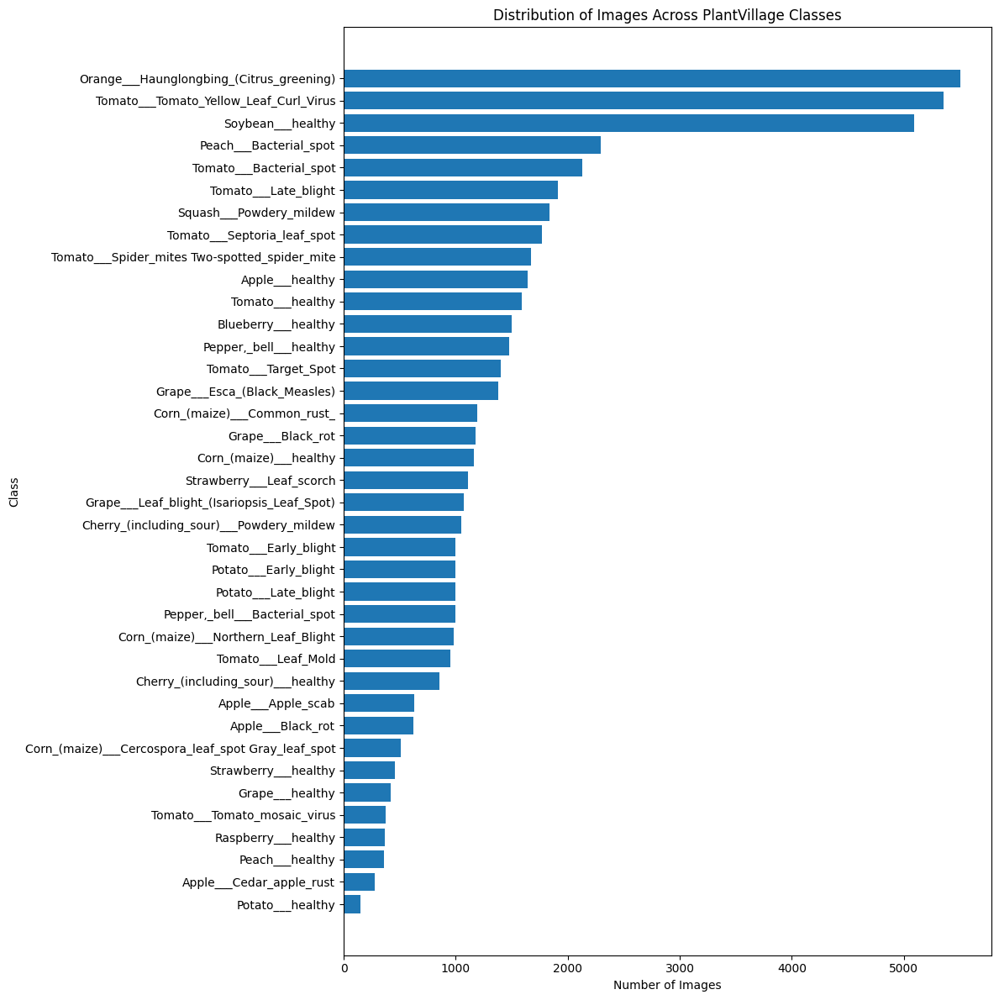

In [15]:
# Cell 14: Visualise class distribution
plt.figure(figsize=(12, 12))

plt.barh(
    class_distribution["class_name"],
    class_distribution["image_count"]
)

plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.title("Distribution of Images Across PlantVillage Classes")

# Largest class at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [16]:
# Cell 15: Quantify class imbalance
class_counts = class_distribution["image_count"]

largest_class = class_distribution.iloc[0]
smallest_class = class_distribution.iloc[-1]

mean_count = class_counts.mean()
median_count = class_counts.median()
std_count = class_counts.std()

imbalance_ratio = (
    largest_class["image_count"] /
    smallest_class["image_count"]
)

print("=" * 55)
print("CLASS IMBALANCE SUMMARY")
print("=" * 55)

print(
    f"Largest class: {largest_class['class_name']} "
    f"({largest_class['image_count']:,} images)"
)

print(
    f"Smallest class: {smallest_class['class_name']} "
    f"({smallest_class['image_count']:,} images)"
)

print(f"\nMean images per class : {mean_count:.2f}")
print(f"Median images per class : {median_count:.2f}")
print(f"Standard deviation      : {std_count:.2f}")
print(f"Max-to-min ratio        : {imbalance_ratio:.2f}:1")

CLASS IMBALANCE SUMMARY
Largest class: Orange___Haunglongbing_(Citrus_greening) (5,507 images)
Smallest class: Potato___healthy (152 images)

Mean images per class : 1429.08
Median images per class : 1092.50
Standard deviation      : 1271.74
Max-to-min ratio        : 36.23:1


,crop,image_count,percentage
0,Tomato,18160,33.440751
1,Orange,5507,10.140871
2,Soybean,5090,9.372986
3,Grape,4062,7.479974
4,Corn_(maize),3852,7.093269
5,Apple,3171,5.839241
6,Peach,2657,4.892735
7,"Pepper,_bell",2475,4.557591
8,Potato,2152,3.962803
9,Cherry_(including_sour),1906,3.509806


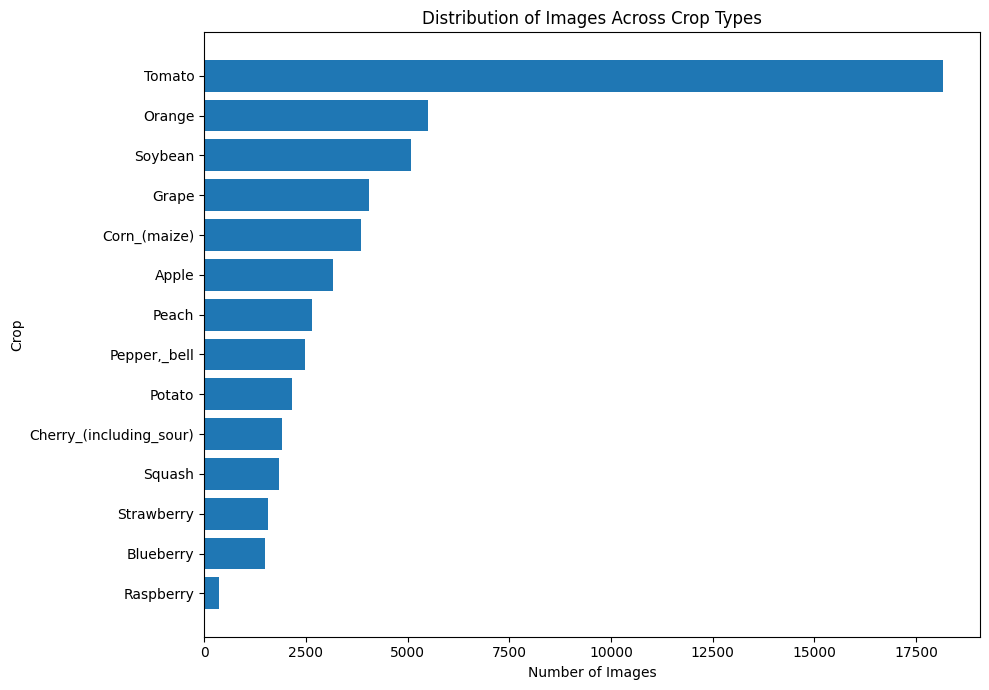

In [17]:
# Cell 16: Distribution by crop
crop_distribution = (
    df["crop"]
    .value_counts()
    .rename_axis("crop")
    .reset_index(name="image_count")
)

crop_distribution["percentage"] = (
    crop_distribution["image_count"] / len(df) * 100
)

display(crop_distribution)

# Visualise
plt.figure(figsize=(10, 7))

plt.barh(
    crop_distribution["crop"],
    crop_distribution["image_count"]
)

plt.xlabel("Number of Images")
plt.ylabel("Crop")
plt.title("Distribution of Images Across Crop Types")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [18]:
# Cell 17: Number of classes epr crop
classes_per_crop = (
    df[["crop", "class_name"]]
    .drop_duplicates()
    .groupby("crop")
    .size()
    .reset_index(name="number_of_classes")
    .sort_values(
        "number_of_classes",
        ascending=False
    )
    .reset_index(drop=True)
)

display(classes_per_crop)

,crop,number_of_classes
0,Tomato,10
1,Apple,4
2,Grape,4
3,Corn_(maize),4
4,Potato,3
5,Cherry_(including_sour),2
6,Strawberry,2
7,Peach,2
8,"Pepper,_bell",2
9,Blueberry,1


,health_status,image_count,percentage
0,Diseased,39221,72.223552
1,Healthy,15084,27.776448


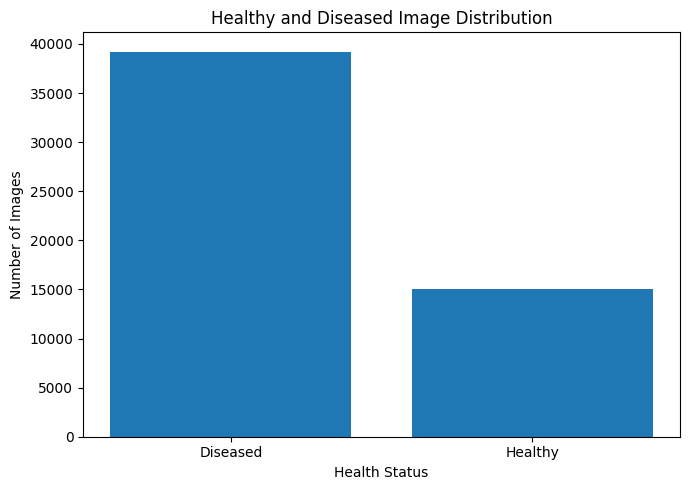

In [19]:
# Cell 18: Healthy vs diseased distribution
health_distribution = (
    df["health_status"]
    .value_counts()
    .rename_axis("health_status")
    .reset_index(name="image_count")
)

health_distribution["percentage"] = (
    health_distribution["image_count"] / len(df) * 100
)

display(health_distribution)

# Visualise
plt.figure(figsize=(7, 5))

plt.bar(
    health_distribution["health_status"],
    health_distribution["image_count"]
)

plt.xlabel("Health Status")
plt.ylabel("Number of Images")
plt.title("Healthy and Diseased Image Distribution")

plt.tight_layout()
plt.show()

In [20]:
# Containers for image properties
widths = []
heights = []
modes = []
valid_images = []
corrupted_files = []

for index, row in df.iterrows():
    file_path = row["filepath"]

    try:
        with Image.open(file_path) as img:
            width, height = img.size

            widths.append(width)
            heights.append(height)
            modes.append(img.mode)
            valid_images.append(True)

    except Exception as e:
        widths.append(np.nan)
        heights.append(np.nan)
        modes.append(None)
        valid_images.append(False)

        corrupted_files.append({
            "filepath": file_path,
            "error": str(e)
        })

# Add properties to the main DataFrame
df["width"] = widths
df["height"] = heights
df["colour_mode"] = modes
df["valid_image"] = valid_images

print("Image property scan completed.")
print(f"Valid images     : {df['valid_image'].sum():,}")
print(f"Corrupted images : {(~df['valid_image']).sum():,}")

Image property scan completed.
Valid images     : 54,305
Corrupted images : 0


In [21]:
# Cell 20: Inspect image dimensions
dimension_distribution = (
    df[df["valid_image"]]
    .groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
    .reset_index(drop=True)
)

print("Number of unique image dimesions:",
      len(dimension_distribution))

display(dimension_distribution.head(20))

# Simple summary
valid_df = df[df["valid_image"]]

print("=" * 50)
print("IMAGE DIMENSION SUMMARY")
print("=" * 50)

print(f"Minimum width  : {valid_df['width'].min():.0f} px")
print(f"Maximum width  : {valid_df['width'].max():.0f} px")
print(f"Minimum height : {valid_df['height'].min():.0f} px")
print(f"Maximum height : {valid_df['height'].max():.0f} px")

print("\nMost common dimensions:")

display(
    dimension_distribution.head(10)
)

Number of unique image dimesions: 1


,width,height,image_count
0,256,256,54305


IMAGE DIMENSION SUMMARY
Minimum width  : 256 px
Maximum width  : 256 px
Minimum height : 256 px
Maximum height : 256 px

Most common dimensions:


,width,height,image_count
0,256,256,54305


In [22]:
# Cell 21: Check colour modes
colour_mode_distribution = (
    df["colour_mode"]
    .value_counts(dropna=False)
    .rename_axis("colour_mode")
    .reset_index(name="image_count")
)

colour_mode_distribution["percentage"] = (
    colour_mode_distribution["image_count"]
    / len(df) * 100
)

display(colour_mode_distribution)

,colour_mode,image_count,percentage
0,RGB,54304,99.998159
1,RGBA,1,0.001841


In [23]:
# Cell 22: Inspect corrupted files
if len(corrupted_files) == 0:
  print("No corrupted images were detected.")
else:
  corrupted_df = pd.DataFrame(corrupted_files)

  print(f"Corrupted images detected: {len(corrupted_df)}")
  display(corrupted_df)

No corrupted images were detected.


In [24]:
# Cell 23: Check exact duplicate files
import hashlib

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
      for chunk in iter(lambda: f.read(8192), b""):
        sha256.update(chunk)

    return sha256.hexdigest()

df["sha256"] = df["filepath"].apply(calculate_sha256)

print("SHA-256 hashes generated for all images.")

# Identify duplicate groups
duplicate_mask = df.duplicated(
    subset="sha256",
    keep=False
)

duplicate_df = (
    df[duplicate_mask]
    .sort_values("sha256")
    .reset_index(drop=True)
)

unique_duplicate_hashes = duplicate_df["sha256"].nunique()

# Number of extra copies beyond one original per group
duplicate_copies = (
    len(duplicate_df) - unique_duplicate_hashes
)

print("=" * 50)
print("EXACT DUPLICATE SUMMARY")
print("=" * 50)

print(f"Total images:               {len(df):,}")
print(f"Images in duplicate groups: {len(duplicate_df):,}")
print(f"Duplicate groups:           {unique_duplicate_hashes:,}")
print(f"Extra duplicate copies:     {duplicate_copies:,}")

SHA-256 hashes generated for all images.
EXACT DUPLICATE SUMMARY
Total images:               54,305
Images in duplicate groups: 42
Duplicate groups:           21
Extra duplicate copies:     21


We found 21 exact duplicate groups, involving 42 files. That means there are 21 additional copies among 54,305 images, about 0.039% of the dataset. The proportion is tiny, but the methodological issue matters more than the percentage: we should prevent identical copies from being separated across training and test sets later.

In [25]:
# Cell 24: Identiify the RGBA image
rgba_images = df[df["colour_mode"] != "RGB"][
    ["filepath", "filename", "class_name", "colour_mode"]
]

display(rgba_images)

,filepath,filename,class_name,colour_mode
23906,/root/.cache/kagglehub/datasets/aftaabahmedsha...,42f083e2-272d-4f83-ad9a-573ee90e50ec___Screen ...,"Pepper,_bell___healthy",RGBA


In [26]:
# Cell 25: Inspect all exact duplicate groups

# Create a copy for duplicate analysis
duplicate_analysis = duplicate_df.copy()

# Assign a readable group numebr to each unique duplicate hash
duplicate_analysis["duplicate_group"] = (
    duplicate_analysis.groupby("sha256").ngroup() + 1
)

display(
    duplicate_analysis[
        [
            "duplicate_group",
            "filename",
            "class_name",
            "crop",
            "condition",
            "sha256"
        ]
    ]
)

,duplicate_group,filename,class_name,crop,condition,sha256
0,1,a5de43e7-fc2f-4a14-a8e6-c0f2f94c84f1___GH_HL L...,Tomato___healthy,Tomato,healthy,12852b3616bcf0ba39b03b5677e74f50f5f6abf4d38957...
1,1,488feb1c-4b9f-44e7-8aa6-4103a9601f5f___GH_HL L...,Tomato___healthy,Tomato,healthy,12852b3616bcf0ba39b03b5677e74f50f5f6abf4d38957...
2,2,f2cda910-55c7-46d7-b1a2-9a3bb9792148___RS_HL 6...,Apple___healthy,Apple,healthy,262198126fd6d982126b69261723e13abb36b383138797...
3,2,fdbfa6f7-f887-442d-8df1-1f0cf839fc4d___RS_HL 6...,Apple___healthy,Apple,healthy,262198126fd6d982126b69261723e13abb36b383138797...
4,3,068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL L...,Tomato___healthy,Tomato,healthy,2a05a74db3a270ac0ec77c00ebe89a332eed5898194351...
5,3,34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL L...,Tomato___healthy,Tomato,healthy,2a05a74db3a270ac0ec77c00ebe89a332eed5898194351...
6,4,5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 L...,Tomato___Late_blight,Tomato,Late_blight,2aeb7479e975df37dfb54aa7b403f57f2ad90b018c3780...
7,4,e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 L...,Tomato___Late_blight,Tomato,Late_blight,2aeb7479e975df37dfb54aa7b403f57f2ad90b018c3780...
8,5,9662364c-aaba-45e3-b907-10792d60578c___GH_HL L...,Tomato___healthy,Tomato,healthy,32e9ffabaa054c19ae8df95e94fbd7a25105defdea1214...
9,5,d2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL L...,Tomato___healthy,Tomato,healthy,32e9ffabaa054c19ae8df95e94fbd7a25105defdea1214...


In [27]:
# Cell 26: Check whether duplicates cross class boundaries
duplicate_class_check = (
    duplicate_analysis
    .groupby("sha256")
    .agg(
        number_of_files=("filepath", "count"),
        number_of_classes=("class_name", "nunique"),
        classes=("class_name", lambda x: list(sorted(set(x))))
    )
    .reset_index()
)

cross_class_duplicates = duplicate_class_check[
    duplicate_class_check["number_of_classes"] > 1
]

print("=" * 55)
print("CROSS-CLASS DUPLICATE CHECK")
print("=" * 55)

print(f"Total duplicate groups : {len(duplicate_class_check)}")
print(f"Cross-class groups     : {len(cross_class_duplicates)}")

if len(cross_class_duplicates) == 0:
    print("\nNo exact duplicates occur across different classes.")
else:
    print("\nWARNING: Exact duplicates were found across different classes.")
    display(cross_class_duplicates)

CROSS-CLASS DUPLICATE CHECK
Total duplicate groups : 21
Cross-class groups     : 0

No exact duplicates occur across different classes.


In [28]:
# Cell 27: Check duplicates by class
duplicate_class_distribution = (
    duplicate_analysis
    .groupby("class_name")
    .agg(
        images_in_duplicate_groups=("filepath", "count"),
        duplicate_groups=("sha256", "nunique")
    )
    .reset_index()
    .sort_values(
        "images_in_duplicate_groups",
        ascending=False
    )
    .reset_index(drop=True)
)

display(duplicate_class_distribution)

,class_name,images_in_duplicate_groups,duplicate_groups
0,Tomato___Late_blight,16,8
1,Apple___healthy,14,7
2,Tomato___healthy,12,6


In [29]:
# Cell 28: Check whether any group contains more than two copies
duplicate_group_sizes = (
    duplicate_analysis
    .groupby("sha256")
    .size()
    .value_counts()
    .sort_index()
)

print("Duplicate group size distribution:")
print(duplicate_group_sizes)

Duplicate group size distribution:
2    21
Name: count, dtype: int64


The 21 exact duplicate groups are all within the same class, and every group is just a pair. They are concentrated in only three classes: Tomato Late Blight, Apple Healthy, and Tomato Healthy.

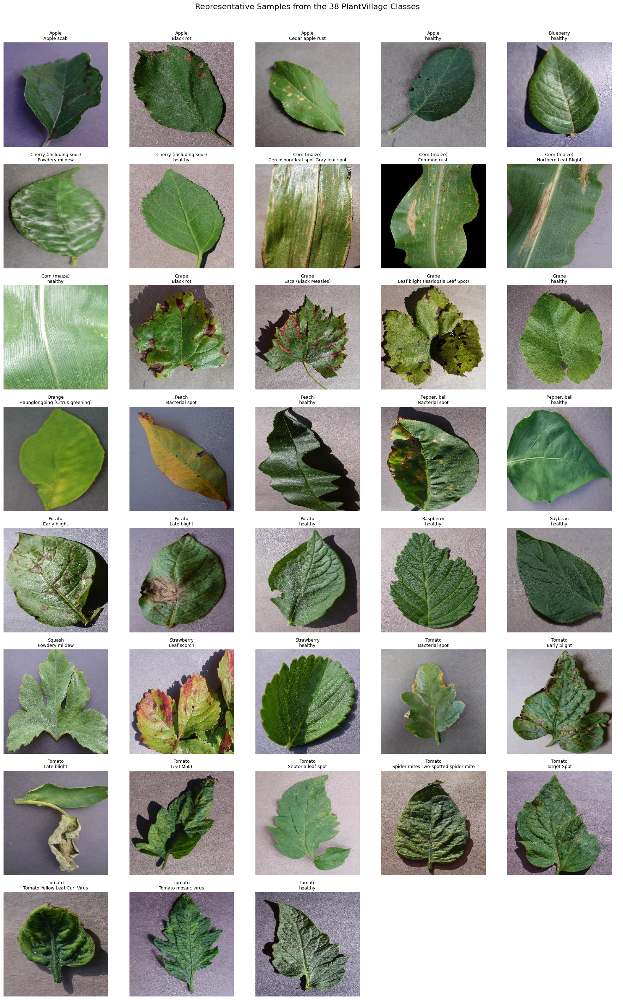

In [30]:
# Cell 29: Display one sample from every class

# Select one reproducible sample from each class
sample_images = (
    df.groupby("class_name", group_keys=False)
      .sample(n=1, random_state=42)
      .sort_values("class_name")
      .reset_index(drop=True)
)

fig, axes = plt.subplots(8, 5, figsize=(18, 28))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_images.iterrows()):
    with Image.open(row["filepath"]) as img:
        ax.imshow(img.convert("RGB"))

    # Make long labels easier to read
    display_name = (
        row["class_name"]
        .replace("___", "\n")
        .replace("_", " ")
    )

    ax.set_title(display_name, fontsize=9)
    ax.axis("off")

# Hide unused subplot spaces
for ax in axes[len(sample_images):]:
    ax.axis("off")

plt.suptitle(
    "Representative Samples from the 38 PlantVillage Classes",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

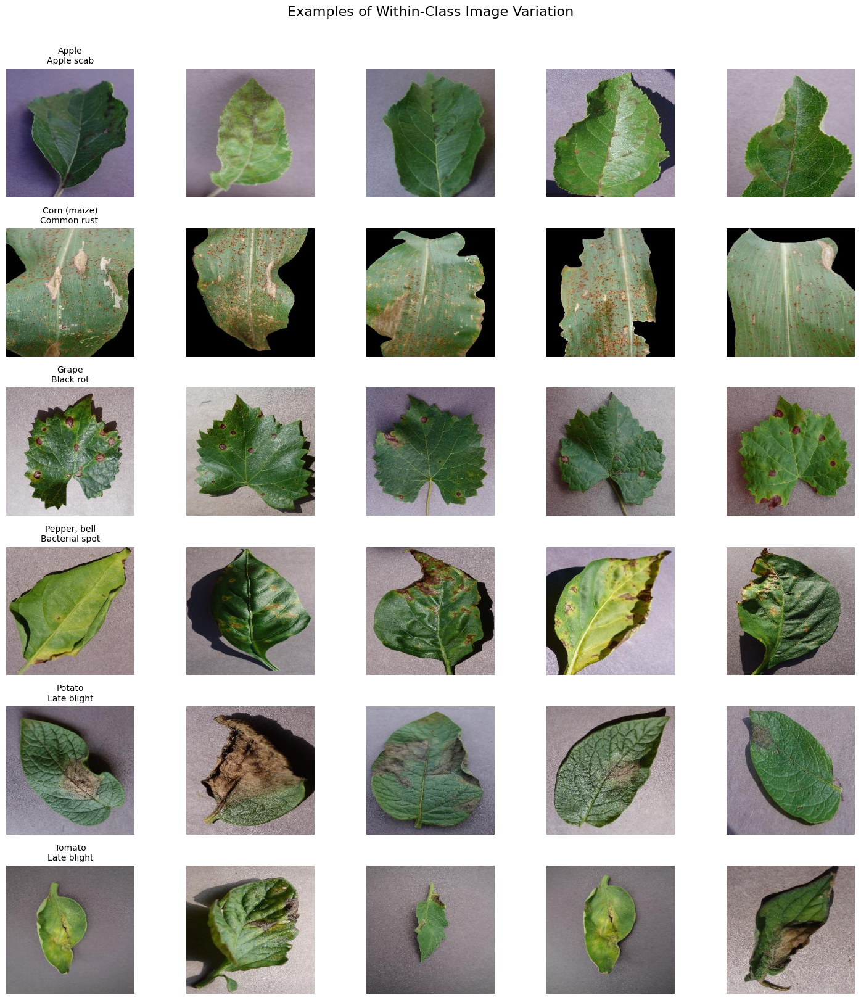

In [31]:
# Cell 30: Show multiple samples from selected classes

# Select several classes across the dataset
selected_classes = [
    "Apple___Apple_scab",
    "Corn_(maize)___Common_rust_",
    "Grape___Black_rot",
    "Pepper,_bell___Bacterial_spot",
    "Potato___Late_blight",
    "Tomato___Late_blight"
]

samples_per_class = 5

fig, axes = plt.subplots(
    len(selected_classes),
    samples_per_class,
    figsize=(15, 16)
)

for row_idx, class_name in enumerate(selected_classes):

    class_samples = (
        df[df["class_name"] == class_name]
        .sample(
            n=samples_per_class,
            random_state=42
        )
    )

    for col_idx, (_, sample) in enumerate(class_samples.iterrows()):

        with Image.open(sample["filepath"]) as img:
            axes[row_idx, col_idx].imshow(
                img.convert("RGB")
            )

        axes[row_idx, col_idx].axis("off")

        if col_idx == 0:
            display_name = (
                class_name
                .replace("___", "\n")
                .replace("_", " ")
            )

            axes[row_idx, col_idx].set_title(
                display_name,
                fontsize=10
            )

plt.suptitle(
    "Examples of Within-Class Image Variation",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [32]:
# Cell 31: Create a final EDA summary table
eda_summary = pd.DataFrame({
    "Characteristic": [
        "Total images",
        "Number of classes",
        "Number of crop types",
        "Healthy images",
        "Diseased images",
        "Image dimensions",
        "RGB images",
        "RGBA images",
        "Corrupted images",
        "Largest class size",
        "Smallest class size",
        "Max-to-min class ratio",
        "Exact duplicate groups",
        "Extra exact duplicate copies",
        "Cross-class duplicate groups"
    ],

    "Result": [
        f"{len(df):,}",
        df["class_name"].nunique(),
        df["crop"].nunique(),
        f"{(df['health_status'] == 'Healthy').sum():,}",
        f"{(df['health_status'] == 'Diseased').sum():,}",
        "256 × 256",
        f"{(df['colour_mode'] == 'RGB').sum():,}",
        f"{(df['colour_mode'] == 'RGBA').sum():,}",
        f"{(~df['valid_image']).sum():,}",
        f"{class_distribution['image_count'].max():,}",
        f"{class_distribution['image_count'].min():,}",
        f"{imbalance_ratio:.2f}:1",
        unique_duplicate_hashes,
        duplicate_copies,
        len(cross_class_duplicates)
    ]
})

display(eda_summary)

,Characteristic,Result
0,Total images,"54,305"
1,Number of classes,38
2,Number of crop types,14
3,Healthy images,"15,084"
4,Diseased images,"39,221"
5,Image dimensions,256 × 256
6,RGB images,"54,304"
7,RGBA images,1
8,Corrupted images,0
9,Largest class size,"5,507"
